In [2]:
import numpy as np
import pandas as pd
from pathlib import Path


In [3]:
# Folder containing this notebook
PROJECT_DIR = Path.cwd().parent

# Path to the CSV file
data_path = PROJECT_DIR / "Initial data" / "LPI_final.csv"
dflp = pd.read_csv(data_path)
# ============================================================
# 0. INPUT DATA
# ============================================================
# Assumes dflp already contains the 96 economies and these columns:
# REF_AREA_LABEL, Aviation connectivity, Aviation dwell time,
# B2B postal connectivity, B2B postal delivery time,
# Maritime connectivity, Container dwell time

criteria = [
    "Maritime connectivity",          # C1: higher is better
    "Container dwell time",           # C2: lower is better
    "Aviation connectivity",          # C3: higher is better
    "Aviation dwell time",            # C4: lower is better
    "B2B postal connectivity",        # C5: higher is better
    "B2B postal delivery time"        # C6: lower is better
]

# 1 = higher is better; -1 = lower is better
directions = np.array([1, -1, 1, -1, 1, -1])

# Aggregated BWM weights
weights = np.array([
    0.1858,  # C1 Maritime connectivity
    0.2524,  # C2 Container import dwell time
    0.1358,  # C3 Aviation connectivity
    0.2166,  # C4 Aviation dwell time
    0.0629,  # C5 B2B postal connectivity
    0.1462   # C6 B2B postal delivery time
], dtype=float)

# Normalise to account for rounding in the displayed weights
weights = weights / weights.sum()

# Group thresholds
q = np.array([3.5, 1.25, 5.5, 1.25, 5.0, 1.15])
p = np.array([10.0, 4.0, 14.0, 2.5, 16.0, 3.0])

# None means no veto for that criterion
v = [None, 6.0, None, 5.5, 25.0, 6.0]

lambda_cut = 0.7

# ============================================================
# 1. PREPARE THE PERFORMANCE MATRIX
# ============================================================

alternatives = dflp["REF_AREA_LABEL"].astype(str).to_numpy()
X = dflp[criteria].to_numpy(dtype=float)

if np.isnan(X).any():
    raise ValueError("The performance matrix contains missing values.")

if len(alternatives) != len(set(alternatives)):
    print("Warning: alternative labels are not unique.")

n_alternatives, n_criteria = X.shape

assert n_criteria == len(weights) == len(q) == len(p) == len(v)
assert np.all(q <= p)
assert np.all(weights >= 0)
assert np.isclose(weights.sum(), 1.0)

for j in range(n_criteria):
    if v[j] is not None and v[j] <= p[j]:
        raise ValueError(f"Veto threshold must exceed p for {criteria[j]}.")

# Delta[i, k, j] is favourable to alternative i when positive.
# Higher-is-better: X_i - X_k
# Lower-is-better: X_k - X_i
Delta = np.empty((n_alternatives, n_alternatives, n_criteria))

for j in range(n_criteria):
    if directions[j] == 1:
        Delta[:, :, j] = X[:, j, None] - X[None, :, j]
    else:
        Delta[:, :, j] = X[None, :, j] - X[:, j, None]

# ============================================================
# 2. LOCAL CONCORDANCE c_j(a S b)
# ============================================================

local_concordance = np.ones_like(Delta)

for j in range(n_criteria):
    diff = Delta[:, :, j]

    fully_supported = diff >= -q[j]
    opposed = diff <= -p[j]
    intermediate = ~(fully_supported | opposed)

    local_concordance[:, :, j] = np.where(
        fully_supported,
        1.0,
        np.where(
            opposed,
            0.0,
            (diff + p[j]) / (p[j] - q[j])
        )
    )

# Comprehensive / weighted concordance matrix
C = np.sum(local_concordance * weights[None, None, :], axis=2)

# ============================================================
# 3. DISCORDANCE d_j(a S b)
# ============================================================

discordance = np.zeros_like(Delta)

for j in range(n_criteria):
    # No veto: no discordance penalty from this criterion
    if v[j] is None:
        continue

    diff = Delta[:, :, j]
    veto_threshold = v[j]

    full_discordance = diff <= -veto_threshold
    no_discordance = diff >= -p[j]
    intermediate = ~(full_discordance | no_discordance)

    discordance[:, :, j] = np.where(
        full_discordance,
        1.0,
        np.where(
            no_discordance,
            0.0,
            (-diff - p[j]) / (veto_threshold - p[j])
        )
    )

# ============================================================
# 4. CREDIBILITY MATRIX sigma(a S b)
# ============================================================

Sigma = C.copy()

for j in range(n_criteria):
    d = discordance[:, :, j]

    # Apply the correction only when discordance exceeds
    # comprehensive concordance.
    mask = d > C

    factor = np.ones_like(C)
    factor[mask] = (1.0 - d[mask]) / (1.0 - C[mask])

    Sigma *= factor

# Protect against floating-point noise
Sigma = np.clip(Sigma, 0.0, 1.0)

# Diagonal: every alternative is equivalent to itself
np.fill_diagonal(C, 1.0)
np.fill_diagonal(Sigma, 1.0)
for j in range(n_criteria):
    np.fill_diagonal(discordance[:, :, j], 0.0)

# ============================================================
# 5. APPLY THE CREDIBILITY CUT-OFF
# ============================================================

# 1 means alternative i outranks alternative k
M = (Sigma >= lambda_cut).astype(int)

# Do not count self-comparisons in the incoming/outgoing counts
np.fill_diagonal(M, 0)

# Outgoing: how many other alternatives this alternative outranks
W = M.sum(axis=1)

# Incoming: how many alternatives outrank this alternative
S = M.sum(axis=0)

# Qualification score 
qualification = W - S

ranking = pd.DataFrame({
    "Economy": alternatives,
    "Outranking count": W,
    "Incoming count": S,
    "Qualification": qualification
})

# Competition ranking: tied qualification scores receive tied ranks
ranking["Rank"] = (
    ranking["Qualification"]
    .rank(method="min", ascending=False)
    .astype(int)
)

ranking = ranking.sort_values(
    ["Rank", "Economy"]
).reset_index(drop=True)

# ============================================================
# 6. DISPLAY RESULTS
# ============================================================

print("Number of alternatives:", n_alternatives)
print("Number of criteria:", n_criteria)
print("Sum of weights:", weights.sum())
print("Credibility cut-off lambda:", lambda_cut)

print("\nAggregated weights:")
print(pd.DataFrame({
    "Criterion": criteria,
    "Weight": weights,
    "q": q,
    "p": p,
    "v": ["No veto" if x is None else x for x in v]
}).to_string(index=False))

print("\nWeighted concordance matrix:")
print(pd.DataFrame(C, index=alternatives, columns=alternatives).round(3))

print("\nCredibility matrix:")
print(pd.DataFrame(Sigma, index=alternatives, columns=alternatives).round(3))

print("\nBinary outranking matrix:")
print(pd.DataFrame(M, index=alternatives, columns=alternatives))

print("\nFinal ranking:")
print(ranking.to_string(index=False))

# ============================================================
# 7. OPTIONAL: EXPORT MATRICES AND RANKING
# ============================================================

pd.DataFrame(C, index=alternatives, columns=alternatives).to_csv(
    "electre_concordance.csv"
)

pd.DataFrame(Sigma, index=alternatives, columns=alternatives).to_csv(
    "electre_credibility.csv"
)

pd.DataFrame(M, index=alternatives, columns=alternatives).to_csv(
    "electre_outranking.csv"
)

ranking.to_csv("electre_iii_ranking.csv", index=False)

# Export each criterion's discordance matrix separately
for j, criterion in enumerate(criteria):
    safe_name = (
        criterion.lower()
        .replace(" ", "_")
        .replace(",", "")
    )
    pd.DataFrame(
        discordance[:, :, j],
        index=alternatives,
        columns=alternatives
    ).to_csv(f"discordance_{safe_name}.csv")

print("\nMatrices and ranking exported successfully.")


Number of alternatives: 96
Number of criteria: 6
Sum of weights: 1.0
Credibility cut-off lambda: 0.7

Aggregated weights:
               Criterion   Weight    q    p       v
   Maritime connectivity 0.185856 3.50 10.0 No veto
    Container dwell time 0.252476 1.25  4.0     6.0
   Aviation connectivity 0.135841 5.50 14.0 No veto
     Aviation dwell time 0.216665 1.25  2.5     5.5
 B2B postal connectivity 0.062919 5.00 16.0    25.0
B2B postal delivery time 0.146244 1.15  3.0     6.0

Weighted concordance matrix:
                      Aruba  Angola  United Arab Emirates  Argentina  \
Aruba                 1.000   0.650                 0.516      0.615   
Angola                0.637   1.000                 0.156      0.585   
United Arab Emirates  1.000   1.000                 1.000      1.000   
Argentina             0.854   0.811                 0.354      1.000   
Antigua and Barbuda   0.819   0.758                 0.469      0.801   
...                     ...     ...                 

### Making CSV to compare ranking between electre III and reeference ranking.

In [4]:
# Folder containing this notebook
PROJECT_DIR = Path.cwd().parent

# Path to the CSV file
data_path_electre_iii = PROJECT_DIR / "4. Electre Rankings" / "electre_iii_ranking.csv"
data_path_reference_ranking = PROJECT_DIR / "5. Reference Rankings" / "reference_ranking.csv"



electre_df=pd.read_csv(data_path_electre_iii)
reference_df=pd.read_csv(data_path_reference_ranking)
# reference_df=pd.read_csv("reference_ranking.csv")


# 2. Keep only the required columns and standardize their names
electre_df = electre_df[["Economy", "Rank"]].rename(
    columns={"Rank": "ELECTRE ranking"}
)

reference_df = reference_df[["REF_AREA_LABEL", "Rank"]].rename(
    columns={
        "REF_AREA_LABEL": "Economy",
        "Rank": "Reference ranking"
    }
)

# 3. Merge both rankings using the country/economy name
common_ranking = pd.merge(
    electre_df,
    reference_df,
    on="Economy",
    how="outer"
)

# 4. Sort by ELECTRE ranking
common_ranking = common_ranking.sort_values(
    by="ELECTRE ranking",
    ascending=True,
    na_position="last"
).reset_index(drop=True)

# 5. Export the combined CSV
common_ranking.to_csv("electre_vs_reference_ranking.csv", index=False)

# 6. Display the result
print(common_ranking.head(10))
print("\nCombined ranking exported successfully!")


          Economy  ELECTRE ranking  Reference ranking
0   United States                1                  1
1  United Kingdom                2                  2
2         Germany                3                  5
3     Netherlands                4                  3
4          France                5                  4
5          Canada                6                 12
6         Belgium                7                  6
7           Italy                8                 10
8           Spain                8                  8
9       Singapore               10                  7

Combined ranking exported successfully!


#### plotting the insights

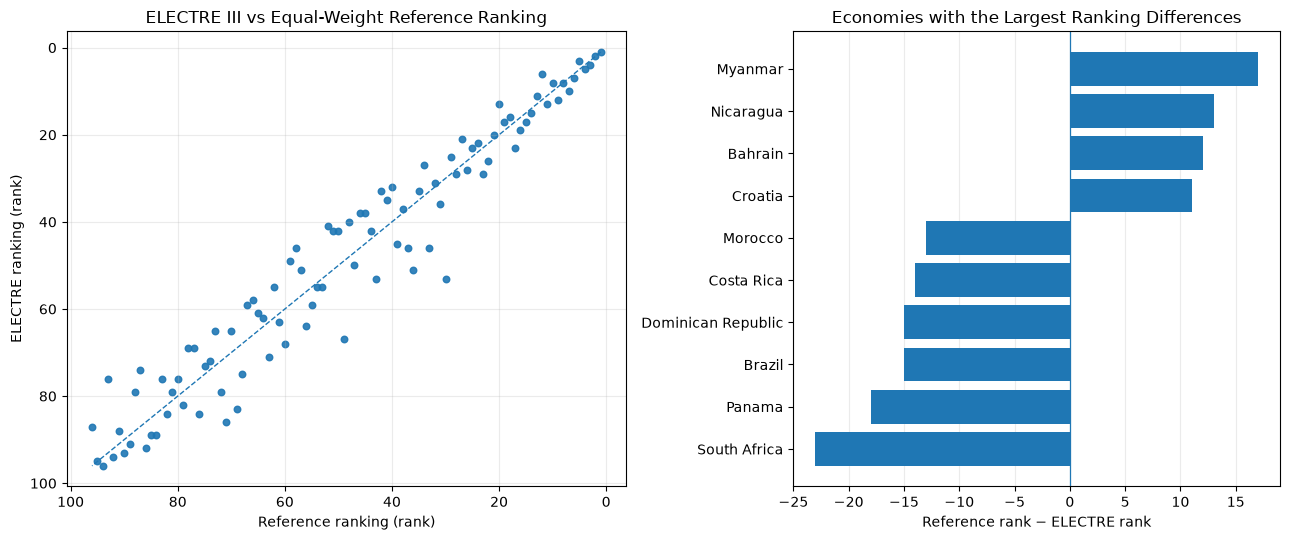

Economies compared: 96
Figure saved to: e:\TU DELFT\Year 1\Q1\MCDA\asgn_2\MCDA-Assignment-2\6. Final Comparison\electre_vs_reference_ranking.png


In [5]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# --------------------------------------------------
# 1. Load the updated rankings
# --------------------------------------------------
PROJECT_DIR = Path.cwd().parent

electre_df = pd.read_csv(
    PROJECT_DIR / "4. Electre Rankings" / "electre_iii_ranking.csv"
)

reference_df = pd.read_csv(
    PROJECT_DIR / "5. Reference Rankings" / "reference_ranking.csv"
)

electre_df = electre_df[["Economy", "Rank"]].rename(
    columns={"Rank": "ELECTRE ranking"}
)

reference_df = reference_df[["REF_AREA_LABEL", "Rank"]].rename(
    columns={
        "REF_AREA_LABEL": "Economy",
        "Rank": "Reference ranking"
    }
)

# Keep economies present in both rankings
common_ranking = pd.merge(
    electre_df,
    reference_df,
    on="Economy",
    how="inner",
    validate="one_to_one"
)

if common_ranking.empty:
    raise ValueError("No matching economy names found between the CSVs.")

# Positive difference: ELECTRE rank is numerically worse
# Negative difference: ELECTRE rank is numerically better
common_ranking["Rank difference"] = (
    common_ranking["Reference ranking"]
    - common_ranking["ELECTRE ranking"]
)

# Save updated comparison data
output_folder = PROJECT_DIR / "6. Final Comparison"
output_folder.mkdir(parents=True, exist_ok=True)

common_ranking.to_csv(
    output_folder / "electre_vs_reference_ranking.csv",
    index=False
)

# --------------------------------------------------
# 2. Create the two-panel figure
# --------------------------------------------------
fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(13, 5.5),
    gridspec_kw={"width_ratios": [1.15, 1]}
)

# LEFT: Reference ranking vs ELECTRE III ranking
ax1.scatter(
    common_ranking["Reference ranking"],
    common_ranking["ELECTRE ranking"],
    s=22,
    alpha=0.9
)

# Equality line: the two rankings are identical
max_rank = max(
    common_ranking["Reference ranking"].max(),
    common_ranking["ELECTRE ranking"].max()
)
ax1.plot(
    [1, max_rank], [1, max_rank],
    linestyle="--", linewidth=1
)

ax1.set_title("ELECTRE III vs Equal-Weight Reference Ranking")
ax1.set_xlabel("Reference ranking (rank)")
ax1.set_ylabel("ELECTRE ranking (rank)")
ax1.grid(True, alpha=0.25)

# Rank 1 (best) at the top-left
ax1.invert_xaxis()
ax1.invert_yaxis()

# RIGHT: 10 economies with largest absolute rank differences
largest = (
    common_ranking
    .assign(abs_difference=lambda df: df["Rank difference"].abs())
    .nlargest(10, "abs_difference")
    .sort_values("Rank difference")
)

ax2.barh(
    largest["Economy"],
    largest["Rank difference"]
)

ax2.axvline(0, linewidth=0.9)
ax2.set_title("Economies with the Largest Ranking Differences")
ax2.set_xlabel("Reference rank − ELECTRE rank")
ax2.grid(axis="x", alpha=0.25)
ax2.set_axisbelow(True)

plt.tight_layout()

# Save a high-resolution version for your report
figure_path = output_folder / "electre_vs_reference_ranking.png"

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Economies compared:", len(common_ranking))
print("Figure saved to:", figure_path)


In [6]:

import pandas as pd
from scipy.stats import spearmanr
from pathlib import Path

PROJECT_DIR = Path.cwd().parent

electre = pd.read_csv(
    PROJECT_DIR / "4. Electre Rankings" / "electre_iii_ranking.csv"
)

reference = pd.read_csv(
    PROJECT_DIR / "5. Reference Rankings" / "reference_ranking.csv"
)

electre = electre[["Economy", "Rank"]].rename(
    columns={"Rank": "ELECTRE rank"}
)

reference = reference[["REF_AREA_LABEL", "Rank"]].rename(
    columns={
        "REF_AREA_LABEL": "Economy",
        "Rank": "Reference rank"
    }
)

df = electre.merge(reference, on="Economy", how="inner",
                   validate="one_to_one")

# Positive = moved up under ELECTRE III
df["Rank change"] = df["Reference rank"] - df["ELECTRE rank"]
df["Absolute difference"] = df["Rank change"].abs()

# Overall comparison statistics
rho, p_value = spearmanr(df["Reference rank"], df["ELECTRE rank"])
mad = df["Absolute difference"].mean()

print("Economies compared:", len(df))
print(f"Spearman correlation: {rho:.4f}")
print(f"Mean absolute rank difference: {mad:.2f}")

# Largest upward movements
print("\nLargest upward movements under ELECTRE III:")
print(
    df.sort_values("Rank change", ascending=False)
      [["Economy", "Reference rank", "ELECTRE rank", "Rank change"]]
      .head(5).to_string(index=False)
)

# Largest downward movements
print("\nLargest downward movements under ELECTRE III:")
print(
    df.sort_values("Rank change")
      [["Economy", "Reference rank", "ELECTRE rank", "Rank change"]]
      .head(5).to_string(index=False)
)

# Economies with the largest absolute differences
print("\nLargest absolute ranking differences:")
print(
    df.sort_values("Absolute difference", ascending=False)
      [["Economy", "Reference rank", "ELECTRE rank", "Rank change"]]
      .head(10).to_string(index=False)
)


Economies compared: 96
Spearman correlation: 0.9678
Mean absolute rank difference: 5.53

Largest upward movements under ELECTRE III:
  Economy  Reference rank  ELECTRE rank  Rank change
  Myanmar              93            76           17
Nicaragua              87            74           13
  Bahrain              58            46           12
  Croatia              52            41           11
  Georgia              59            49           10

Largest downward movements under ELECTRE III:
           Economy  Reference rank  ELECTRE rank  Rank change
      South Africa              30            53          -23
            Panama              49            67          -18
Dominican Republic              71            86          -15
            Brazil              36            51          -15
        Costa Rica              69            83          -14

Largest absolute ranking differences:
           Economy  Reference rank  ELECTRE rank  Rank change
      South Africa           